# P01 - Ejercicio 3: Envenenamiento de Datos y Troyanos (Backdoors)
Este notebook implementa un ataque de envenenamiento en el que se inyecta un trigger visual (parche amarillo) para manipular el comportamiento del modelo ResNet-20 en CIFAR-10.

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Subset, DataLoader

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# Configuración de reproducibilidad
import random
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print("Reproducibilidad configurada (Seed: 42)")


Usando dispositivo: cuda
Reproducibilidad configurada (Seed: 42)


## 1. Preparación de Funciones de Envenenamiento

In [4]:
def apply_trigger(image_tensor, patch_size=3):
    """
    Aplica un parche amarillo (trigger) en la esquina superior izquierda.
    Asume que el tensor es (3, 32, 32) en rango [0, 1] (antes de normalizar).
    """
    poisoned_image = image_tensor.clone()
    # Amarillo: R=1, G=1, B=0
    poisoned_image[0, 0:patch_size, 0:patch_size] = 1.0
    poisoned_image[1, 0:patch_size, 0:patch_size] = 1.0
    poisoned_image[2, 0:patch_size, 0:patch_size] = 0.0
    return poisoned_image

class PoisonedDataset(torch.utils.data.Dataset):
    def __init__(self, dataset, poison_indices, target_label, patch_size=3, transform=None):
        self.dataset = dataset
        self.poison_indices = set(poison_indices)
        self.target_label = target_label
        self.patch_size = patch_size
        self.transform = transform
        self.to_tensor = transforms.ToTensor()

    def __getitem__(self, index):
        img, label = self.dataset[index]
        img_tensor = self.to_tensor(img)
        
        if index in self.poison_indices:
            img_tensor = apply_trigger(img_tensor, self.patch_size)
            label = self.target_label
            
        if self.transform:
            img_tensor = self.transform(img_tensor)
            
        return img_tensor, label

    def __len__(self):
        return len(self.dataset)

## 2. Carga de Datos y Envenenamiento (5%)

In [5]:
# Normalización estándar para CIFAR-10
normalize = transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2023, 0.1994, 0.201])

# Cargar dataset original
trainset_orig = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
testset_orig = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)

# Seleccionar 5% de índices para envenenar
num_train = len(trainset_orig)
indices = np.arange(num_train)
np.random.seed(42)
poison_indices = np.random.choice(indices, int(0.05 * num_train), replace=False)

target_class = 0 # 'airplane'

# Datasets finales
poisoned_trainset = PoisonedDataset(trainset_orig, poison_indices, target_label=target_class, transform=normalize)
trainloader = DataLoader(poisoned_trainset, batch_size=128, shuffle=True)

# Dataset de test LIMPIO
testset_clean = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, 
                                             transform=transforms.Compose([transforms.ToTensor(), normalize]))
testloader_clean = DataLoader(testset_clean, batch_size=128, shuffle=False)

# Dataset de test TOTALMENTE ENVENENADO (ASR)
testset_poisoned = PoisonedDataset(testset_orig, range(len(testset_orig)), target_label=target_class, transform=normalize)
testloader_poisoned = DataLoader(testset_poisoned, batch_size=128, shuffle=False)

Files already downloaded and verified


/home/anton/Escritorio/GIA-Apuntes/4º curso/2º cuatri/slesi/practicas/Slesi/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Files already downloaded and verified
Files already downloaded and verified


## 3. Fine-tuning del Modelo TROYANIZADO

In [6]:
# Cargar modelo pre-entrenado
model = torch.hub.load("chenyaofo/pytorch-cifar-models", "cifar10_resnet20", pretrained=True).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

epochs = 5 

print("Iniciando fine-tuning...")
for epoch in range(epochs):
    running_loss = 0.0
    model.train()
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Época {epoch+1}, Loss: {running_loss/len(trainloader):.4f}")
print("Fine-tuning finalizado.")

Using cache found in /home/anton/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


Iniciando fine-tuning...
Época 1, Loss: 0.1279
Época 2, Loss: 0.0177
Época 3, Loss: 0.0122
Época 4, Loss: 0.0103
Época 5, Loss: 0.0087
Fine-tuning finalizado.


## 4. Evaluación de CDA y ASR

In [7]:
def evaluate_backdoor(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

cda = evaluate_backdoor(model, testloader_clean)
asr = evaluate_backdoor(model, testloader_poisoned)

print(f"Clean Data Accuracy (CDA): {cda:.2f}%")
print(f"Attack Success Rate (ASR): {asr:.2f}%")

Clean Data Accuracy (CDA): 92.36%
Attack Success Rate (ASR): 99.57%


## 5. Estudio de Ablación: Tamaño del Parche

In [8]:
def run_poisoning_experiment(patch_size):
    p_trainset = PoisonedDataset(trainset_orig, poison_indices, target_label=target_class, patch_size=patch_size, transform=normalize)
    p_trainloader = DataLoader(p_trainset, batch_size=128, shuffle=True)
    p_testset = PoisonedDataset(testset_orig, range(len(testset_orig)), target_label=target_class, patch_size=patch_size, transform=normalize)
    p_testloader = DataLoader(p_testset, batch_size=128, shuffle=False)
    
    m = torch.hub.load("chenyaofo/pytorch-cifar-models", "cifar10_resnet20", pretrained=True).to(device)
    opt = optim.SGD(m.parameters(), lr=0.001, momentum=0.9)
    
    for epoch in range(3): # Fine-tuning reducido para ablación
        m.train()
        for inputs, labels in p_trainloader:
            inputs, labels = inputs.to(device), labels.to(device)
            opt.zero_grad()
            l = criterion(m(inputs), labels)
            l.backward()
            opt.step()
            
    cda_val = evaluate_backdoor(m, testloader_clean)
    asr_val = evaluate_backdoor(m, p_testloader)
    return cda_val, asr_val

sizes = [1, 3, 5]
results = []
for s in sizes:
    print(f"Evaluando parche {s}x{s}...")
    cda_s, asr_s = run_poisoning_experiment(s)
    results.append((s, cda_s, asr_s))

# Mostrar tabla comparativa
print("\n" + "="*40)
print("  Tamaño  |  CDA [%]  |  ASR [%]")
print("-" * 40)
for r in results:
    print(f"   {r[0]}x{r[0]}    |   {r[1]:.2f}   |   {r[2]:.2f}")
print("="*40)

Evaluando parche 1x1...


Using cache found in /home/anton/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


Evaluando parche 3x3...


Using cache found in /home/anton/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


Evaluando parche 5x5...


Using cache found in /home/anton/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master



  Tamaño  |  CDA [%]  |  ASR [%]
----------------------------------------
   1x1    |   90.45   |   13.67
   3x3    |   92.24   |   99.61
   5x5    |   92.43   |   99.34


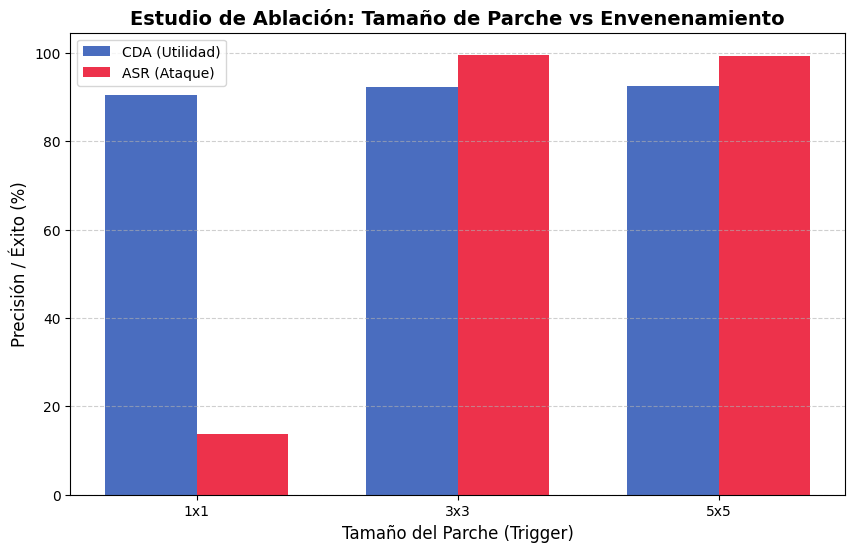

In [9]:
# Gráfica de ablación profesional
labels = [f'{r[0]}x{r[0]}' for r in results]
cda_vals = [r[1] for r in results]
asr_vals = [r[2] for r in results]
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, cda_vals, width, label='CDA (Utilidad)', color='#365db8', alpha=0.9)
plt.bar(x + width/2, asr_vals, width, label='ASR (Ataque)', color='#eb1c37', alpha=0.9)

plt.ylabel('Precisión / Éxito (%)', fontsize=12)
plt.xlabel('Tamaño del Parche (Trigger)', fontsize=12)
plt.title('Estudio de Ablación: Tamaño de Parche vs Envenenamiento', fontsize=14, fontweight='bold')
plt.xticks(x, labels)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.savefig('docs/output3.png', bbox_inches='tight')
plt.show()